# SARIMAX

Modelo lineal de series de tiempo para pronosticar el precio de bolsa de la semana siguiente, hora
por hora. Es el modelo más sencillo de los tres y sirve de punto de comparación para XGBoost y la
LSTM.

El flujo completo está en `5_modelo_sarimax.ipynb`, en la raíz del repositorio. Este notebook muestra las partes principales:
los datos, las funciones de ajuste y pronóstico, las decisiones de cada etapa y el resultado del
test. El test no se vuelve a correr; sus pronósticos se leen de `datos/resultados/modelo_sarimax/`. Lo
único que se estima aquí son modelos con datos hasta 2022, como ejemplo.

## 1. Qué se pronostica

XM publica el precio con dos días de atraso. Si el pronóstico se hace el día $R$, el último precio
conocido es el del día $t = R - 2$, y la semana siguiente va de $t + 3$ a $t + 9$. Son los
horizontes $h = 3$ a $9$, con 24 horas cada uno: 168 precios.

Los tres modelos pronostican lo mismo, el cambio en logaritmo frente al último precio conocido a la
misma hora $H$:

$$y_h = \ln P(t+h,\,H) - \ln P(t,\,H)$$

Hay dos referencias. El ingenuo del día repite el último precio conocido ($\hat y_h = 0$) y el
ingenuo semanal repite el precio del mismo día de la semana en la última semana conocida.

In [1]:
suppressPackageStartupMessages({
  library(forecast)
  library(data.table)
  library(ggplot2)
  library(jsonlite)
})
options(repr.plot.width = 10, repr.plot.height = 4, repr.plot.res = 120, digits = 4)

RAIZ <- "datos"
SAR <- file.path(RAIZ, "resultados/modelo_sarimax")
XGB <- file.path(RAIZ, "resultados/modelo_xgboost")

HORIZONTES <- 3:9
INICIO <- as.Date("2015-03-01")
FIN_ELECCION <- as.Date("2019-12-31")
FIN_VALIDACION <- as.Date("2022-12-31")
BLOQUES <- list("h = 3 a 9" = 3:9, "h = 3" = 3L, "h = 3 a 7" = 3:7, "h = 8 a 9" = 8:9)

AZUL <- "#2a78d6"; VERDE <- "#1baf7a"; GRIS <- "#898781"; GRIS_CLARO <- "#c3c2b7"
AZULES <- c("#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#256abf", "#184f95", "#0d366b")
COLOR_METRICA <- c(MAE = "#5598e7", RMSE = "#0d366b", MBE = "#52514e")
EJE_H <- "h (días desde el último precio conocido)"
tema <- theme_minimal(base_size = 12) +
  theme(plot.title = element_text(size = 12), panel.grid.minor = element_blank(), legend.position = "top")

## 2. Datos

Cada hora del día se trata como una serie diaria aparte. La matriz `LP` tiene una fila por día y
una columna por hora, con el logaritmo del precio. El festivo se conoce de antemano, así que en el
pronóstico entra el del día pronosticado.

In [2]:
tabla <- fread(file.path(RAIZ, "paneles/panel_horario_modelo.csv.gz"),
               select = c("fecha", "hora", "lp", "es_festivo", paste0("es_festivo_h", c(1:7, 14, 30))))
tabla[, fecha := as.Date(fecha)]
setorder(tabla, fecha, hora)

FECHAS <- seq(INICIO, max(tabla$fecha) + 9, by = "day")
LP <- matrix(NA_real_, length(FECHAS), 24)
LP[seq_len(uniqueN(tabla$fecha)), ] <- matrix(tabla$lp, ncol = 24, byrow = TRUE)

# el panel trae el festivo de los días siguientes; con eso el calendario llega hasta t + 9
dia <- tabla[hora == 1]
FEST <- rep(NA_real_, length(FECHAS))
FEST[match(dia$fecha, FECHAS)] <- dia$es_festivo
for (k in c(1:7, 14, 30)) {
  j <- match(dia$fecha + k, FECHAS)
  FEST[j[!is.na(j)]] <- dia[[paste0("es_festivo_h", k)]][!is.na(j)]
}
stopifnot(!anyNA(FEST))
cat(sprintf("%d días, del %s al %s\n", uniqueN(tabla$fecha), min(tabla$fecha), max(tabla$fecha)))

4238 días, del 2015-03-01 al 2026-10-06


La serie de cada hora tiene un ciclo semanal. Se ve en la autocorrelación del cambio diario del
logaritmo del precio en la hora 19, con picos en los rezagos 7, 21 y 28 y uno menor en el 14. Por
eso cada modelo tiene estacionalidad de 7 días. La autocorrelación negativa en el rezago 1 dice
que un salto del precio tiende a devolverse al día siguiente.

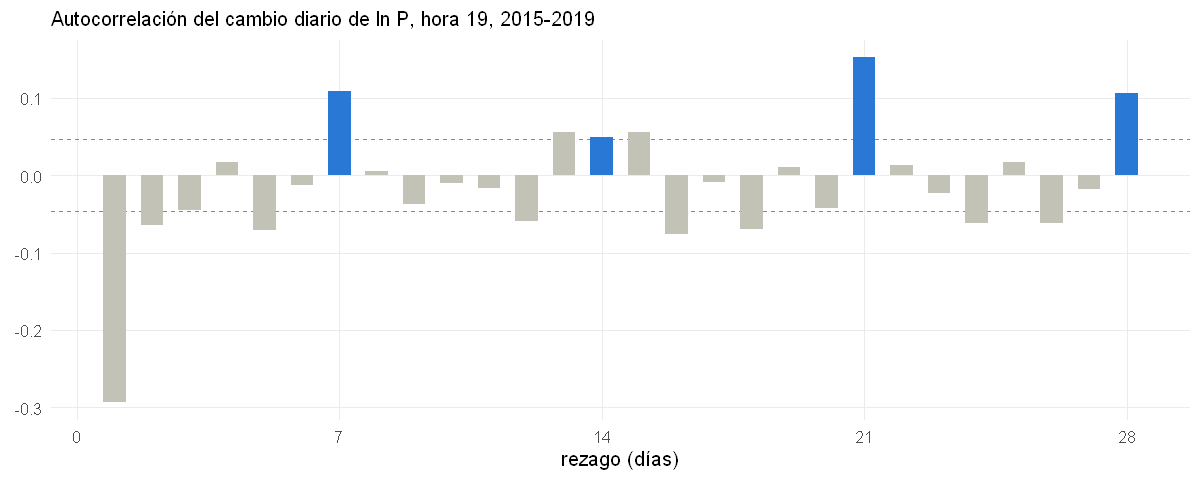

In [3]:
i <- seq_len(match(FIN_ELECCION, FECHAS))
a <- acf(diff(LP[i, 19]), lag.max = 28, plot = FALSE)
banda <- 1.96 / sqrt(length(i) - 1)
ac <- data.table(rezago = 1:28, acf = a$acf[-1])

ggplot(ac, aes(rezago, acf, fill = rezago %% 7 == 0)) +
  geom_hline(yintercept = c(-banda, banda), linetype = "dashed", color = GRIS) +
  geom_col(width = 0.6, show.legend = FALSE) +
  scale_fill_manual(values = c(`FALSE` = GRIS_CLARO, `TRUE` = AZUL)) +
  scale_x_continuous(breaks = seq(0, 28, 7)) +
  labs(title = "Autocorrelación del cambio diario de ln P, hora 19, 2015-2019", x = "rezago (días)", y = NULL) +
  tema

## 3. El modelo

Para cada hora $H$ se estima una regresión con errores SARIMA: el festivo entra en la regresión y
el error sigue un modelo SARIMA con ciclo de 7 días.

$$\ln P_t = \beta\,\text{festivo}_t + \eta_t, \qquad
\phi(B)\,\Phi(B^7)\,(1-B)^d\,(1-B^7)^D\,\eta_t = \theta(B)\,\Theta(B^7)\,\varepsilon_t$$

$B$ es el operador de rezago. La estimación es con el paquete `forecast` de R (Hyndman y
Khandakar, 2008). Todo el flujo usa estas dos funciones, una versión corta de las de
`5_modelo_sarimax.ipynb` sin variables exógenas, porque el modelo final no tiene ninguna:

- `ajustar` estima los coeficientes con los datos hasta una fecha.
- `pronosticar` toma esos coeficientes sin volver a estimarlos, actualiza el estado del modelo con
  los precios conocidos hasta el día $t$ y pronostica 9 días. Se guardan $h = 3$ a $9$.

En la validación y en el test los coeficientes se reestiman el primer día de cada mes con toda la
información anterior, y dentro del mes solo se actualiza el estado. Es el mismo calendario de
XGBoost y la LSTM.

In [4]:
hasta <- function(fin) seq_len(match(fin, FECHAS))

ajustar <- function(H, fin, orden) {
  i <- hasta(fin)
  o <- as.integer(orden)
  Arima(ts(LP[i, H], frequency = 7), order = o[1:3], seasonal = list(order = o[4:6], period = 7),
        xreg = cbind(festivo = FEST[i]), method = "CSS-ML")
}

pronosticar <- function(fit, H, t) {
  i <- hasta(t)
  n <- length(i)
  actual <- Arima(ts(LP[i, H], frequency = 7), model = fit, xreg = cbind(festivo = FEST[i]))
  f <- forecast(actual, xreg = cbind(festivo = FEST[n + 1:9]), h = 9, level = 80)
  data.table(fecha = FECHAS[n], hora = H, h = HORIZONTES, lp_hat = as.numeric(f$mean)[HORIZONTES],
             lo80 = as.numeric(f$lower)[HORIZONTES], hi80 = as.numeric(f$upper)[HORIZONTES])
}

## 4. Órdenes (2015-2019)

Para cada hora, `auto.arima` decidió las diferencias con pruebas (KPSS para $d$ y OCSB para $D$) y
buscó $p$, $q$, $P$ y $Q$ con el menor AICc. Las 24 horas quedaron con una diferencia regular
($d = 1$) y sin diferencia estacional ($D = 0$).

In [5]:
ordenes <- fread(file.path(SAR, "etapa2_ordenes.csv"))
ordenes[, orden := sprintf("(%d,%d,%d)(%d,%d,%d)", p, d, q, P, D, Q)]
ordenes[, .(horas = .N), by = orden][order(-horas)]

orden,horas
<chr>,<int>
"(1,1,2)(0,0,2)",5
"(1,1,2)(0,0,1)",3
"(1,1,1)(0,0,0)",3
"(2,1,1)(0,0,2)",3
"(1,1,3)(0,0,2)",3
"(1,1,2)(1,0,0)",1
"(2,1,2)(0,0,2)",1
"(3,1,3)(0,0,2)",1
"(1,1,1)(0,0,2)",1


Salieron 12 órdenes distintos. El más frecuente, (1,1,2)(0,0,2), aparece en 5 horas y es la
versión con un solo orden para las 24 horas, que en la validación se comparó con la de un orden
por hora.

## 5. Variables exógenas (2015-2019)

Las candidatas fueron las variables base del panel que pasan la misma limpieza que se usó en
XGBoost. Cada una entra con 9 días de rezago, $x(t+h-9)$, para que ya se conozca en $t$ en
cualquier horizonte de la semana. Se aplicaron tres filtros seguidos:

1. Preblanqueo: correlación entre los residuos del precio y de la variable en el rezago 9,
   significativa en al menos 12 de las 24 horas, con corrección de Bonferroni.
2. Selección hacia adelante con el AICc sumado en las 24 horas.
3. Prueba t del coeficiente, con $p < 0{,}05$ en al menos 12 horas.

In [6]:
cand <- fread(file.path(SAR, "etapa3_candidatas.csv"))
print(cand[, .(variables = .N), by = motivo])
cat("\npasan el preblanqueo:", paste(cand[pasa == TRUE, variable], collapse = ", "), "\n\n")
print(fread(file.path(SAR, "etapa3_adelante.csv")))
print(fread(file.path(SAR, "etapa3_pruebas_t.csv")))

                     motivo variables
                     <char>     <int>
1:                candidata       122
2:                inestable         8
3:           casi constante         1
4: nivel que sigue al dólar         2



pasan el preblanqueo: holgura_rel 



    paso          variable aicc_total
   <int>            <char>      <num>
1:     0 (solo calendario)     -23215
2:     1       holgura_rel     -23462


      variable horas_p05 p_mediana  queda
        <char>     <int>     <num> <lgcl>
1: holgura_rel        17  0.005938   TRUE


De 122 candidatas, solo `holgura_rel`, la holgura de capacidad frente a la demanda, pasó el
preblanqueo. Pasó también los otros dos filtros: baja el AICc total y su coeficiente es
significativo en 17 de las 24 horas.

## 6. Validación (2020-2022)

Se compararon tres versiones pronosticando la semana en 2020-2022 y reentrenando cada mes. Una
versión más compleja solo entraba si le ganaba a la anterior con Diebold-Mariano $p < 0{,}05$.

In [7]:
val <- fread(file.path(SAR, "etapa4_comparacion.csv"))
val[, version := c(comun = "un orden para las 24 horas", por_hora = "un orden por hora",
                   exogenas = "un orden y holgura_rel")[version]]
val[, mejora := 100 * (1 - rmse_log / rmse_ingenuo_dia)]
val[, .(version, rmse_log, rmse_ingenuo_dia, mejora, p_contra_anterior = dm_p_contra_anterior)]

version,rmse_log,rmse_ingenuo_dia,mejora,p_contra_anterior
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
un orden para las 24 horas,0.2805,0.2943,4.678,NA
un orden por hora,0.2806,0.2943,4.659,0.8646
un orden y holgura_rel,0.2806,0.2943,4.672,0.9695


Las tres versiones tienen casi el mismo error. Ni el orden por hora ($p = 0{,}86$) ni la variable
exógena ($p = 0{,}97$) mejoran a la versión más simple. `holgura_rel` pasó las pruebas de
2015-2019, pero esas pruebas miden el ajuste dentro de la muestra y a un paso; pronosticando una
semana con datos nuevos no aportó nada.

El modelo final es el mismo para las 24 horas: SARIMAX(1,1,2)(0,0,2) con ciclo de 7 días, festivo y
sin variables exógenas.

### Criterio

Un modelo funciona en un bloque de horizontes si su RMSE en logaritmo es al menos 5% menor que el
del mejor ingenuo y si la prueba de Diebold-Mariano (Diebold y Mariano, 1995) contra ese ingenuo
da $p < 0{,}05$. La prueba usa el promedio diario de la diferencia de los errores al cuadrado, con
varianza de Newey-West (Newey y West, 1987) y $h_{max} - 1 + 7$ rezagos, porque los errores de días seguidos están correlacionados. Las mismas
funciones se usan en los tres modelos.

In [8]:
rmse <- function(e) sqrt(mean(e^2))

newey_west <- function(d, L) {
  n <- length(d)
  u <- d - mean(d)
  v <- mean(u * u)
  for (l in seq_len(min(L, n - 1))) v <- v + 2 * (1 - l / (L + 1)) * mean(u[(l + 1):n] * u[1:(n - l)])
  c(media = mean(d), ee = sqrt(v / n))
}

diebold_mariano <- function(e_a, e_b, fechas, L) {
  d <- as.numeric(tapply(e_a^2 - e_b^2, fechas, mean))
  m <- newey_west(d, L)
  t <- unname(m["media"] / m["ee"])
  c(t = t, p = 2 * pnorm(-abs(t)))
}

completar <- function(p) {
  # agrega a los pronósticos guardados el cambio real y el ingenuo semanal
  d <- copy(p)[, fecha := as.Date(fecha)]
  d[, i := match(fecha, FECHAS)]
  d[, lp_t := LP[cbind(i, hora)]]
  d[, y := LP[cbind(i + h, hora)] - lp_t]
  d[, y_hat := lp_hat - lp_t]
  d[, y_semanal := LP[cbind(i - (7L * ceiling(h / 7) - h), hora)] - lp_t]
  d[]
}

criterio <- function(d) {
  rbindlist(lapply(names(BLOQUES), function(b) {
    g <- d[h %in% BLOQUES[[b]]]
    e <- g$y - g$y_hat
    ing <- list("del día" = g$y, "semanal" = g$y - g$y_semanal)
    ref <- names(which.min(sapply(ing, rmse)))
    r <- diebold_mariano(e, ing[[ref]], g$fecha, max(BLOQUES[[b]]) - 1 + 7)
    mejora <- 100 * (1 - rmse(e) / rmse(ing[[ref]]))
    data.table(bloque = b, rmse = rmse(e), ingenuo = ref, rmse_ingenuo = rmse(ing[[ref]]),
               mejora = mejora, t = r[["t"]], p = r[["p"]], cumple = mejora >= 5 & r[["p"]] < 0.05)
  }))
}

criterio(completar(fread(file.path(SAR, "etapa4_comun.csv.gz"))))

bloque,rmse,ingenuo,rmse_ingenuo,mejora,t,p,cumple
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
h = 3 a 9,0.2805,del día,0.2943,4.678,-2.364,0.018087,FALSE
h = 3,0.2242,del día,0.2400,6.550,-3.035,0.002401,TRUE
h = 3 a 7,0.2627,del día,0.2760,4.792,-2.344,0.019080,FALSE
h = 8 a 9,0.3209,del día,0.3360,4.486,-2.370,0.017776,FALSE


En la validación el modelo elegido mejora 4,7% al ingenuo del día en la semana, con $p = 0{,}018$:
la diferencia es significativa, pero queda justo por debajo del 5%. Solo $h = 3$ pasa el umbral.

## 7. El modelo final en una hora

Como ejemplo, el modelo de la hora 19 estimado con los datos hasta el 31 de diciembre de 2022, que
son los coeficientes con los que arranca el test en enero de 2023.

In [9]:
orden <- unlist(fromJSON(file.path(SAR, "configuracion_final.json"))$ordenes[1, ])
print(orden)
ajustar(19, FIN_VALIDACION, orden)

p d q P D Q 
1 1 2 0 0 2 


Series: ts(LP[i, H], frequency = 7) 
Regression with ARIMA(1,1,2)(0,0,2)[7] errors 

Coefficients:
       ar1     ma1    ma2   sma1   sma2  festivo
      0.83  -1.213  0.270  0.137  0.068   -0.067
s.e.  0.05   0.057  0.037  0.019  0.018    0.013

sigma^2 = 0.0312:  log likelihood = 903.5
AIC=-1793   AICc=-1793   BIC=-1751

`ar1`, `ma1` y `ma2` son la parte regular y `sma1` y `sma2` la parte semanal, sobre el cambio
diario del logaritmo del precio. El coeficiente del festivo es $-0{,}067$: con lo demás igual, un
festivo baja el precio de esa hora alrededor de 6%.

Para revisar si queda estructura en los residuos se usa la prueba de Ljung-Box (Ljung y Box, 1978)
a 14 rezagos en las 24 horas, con el modelo estimado en 2015-2019.

In [10]:
lb <- sapply(1:24, function(H) {
  f <- ajustar(H, FIN_ELECCION, orden)
  Box.test(residuals(f), lag = 14, type = "Ljung-Box", fitdf = sum(orden[c("p", "q", "P", "Q")]))$p.value
})
cat(sprintf("%d de 24 horas sin autocorrelación en los residuos al 5%% (p mediana %.3f)\n", sum(lb > 0.05), median(lb)))
cat("horas con autocorrelación:", which(lb <= 0.05), "\n")

17 de 24 horas sin autocorrelación en los residuos al 5% (p mediana 0.082)


horas con autocorrelación: 3 6 7 15 16 17 22 


En 7 horas queda algo de autocorrelación. Un orden propio para cada hora habría podido reducirla,
pero en la validación esa versión no pronosticó mejor.

## 8. Test: 2023-2025 y 2026

El test se corrió una sola vez, con el modelo congelado, desde cada día de 2023-2025 y de 2026
hasta el 6 de octubre. Se leen los pronósticos guardados y se mide con las funciones de arriba.

In [11]:
test <- rbind(completar(fread(file.path(SAR, "prueba_2023_2025.csv.gz")))[, periodo := "2023-2025"],
              completar(fread(file.path(SAR, "prueba_2026.csv.gz")))[, periodo := "2026"])
cat(sprintf("%s pronósticos\n", format(nrow(test), big.mark = ".", decimal.mark = ",")))
rbind(criterio(test[periodo == "2023-2025"])[, periodo := "2023-2025"],
      criterio(test[periodo == "2026"])[, periodo := "2026"])

228.984 pronósticos


bloque,rmse,ingenuo,rmse_ingenuo,mejora,t,p,cumple,periodo
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<chr>
h = 3 a 9,0.4697,del día,0.5018,6.409,-6.394,1.612e-10,TRUE,2023-2025
h = 3,0.3796,del día,0.4115,7.736,-5.406,6.454e-08,TRUE,2023-2025
h = 3 a 7,0.4418,del día,0.4720,6.404,-6.035,1.586e-09,TRUE,2023-2025
h = 8 a 9,0.5332,del día,0.5698,6.417,-5.984,2.173e-09,TRUE,2023-2025
h = 3 a 9,0.4110,del día,0.4353,5.590,-3.528,4.188e-04,TRUE,2026
h = 3,0.3295,del día,0.3524,6.494,-3.524,4.245e-04,TRUE,2026
h = 3 a 7,0.3860,del día,0.4087,5.563,-3.363,7.722e-04,TRUE,2026
h = 8 a 9,0.4684,del día,0.4964,5.638,-3.230,1.238e-03,TRUE,2026


SARIMAX cumple el criterio en todos los bloques y en los dos periodos, aunque con poco margen sobre
el 5%: 6,4% en 2023-2025 y 5,6% en 2026 en la semana completa.

Mejora frente al ingenuo del día en cada horizonte y en cada año (el año del día del pronóstico):

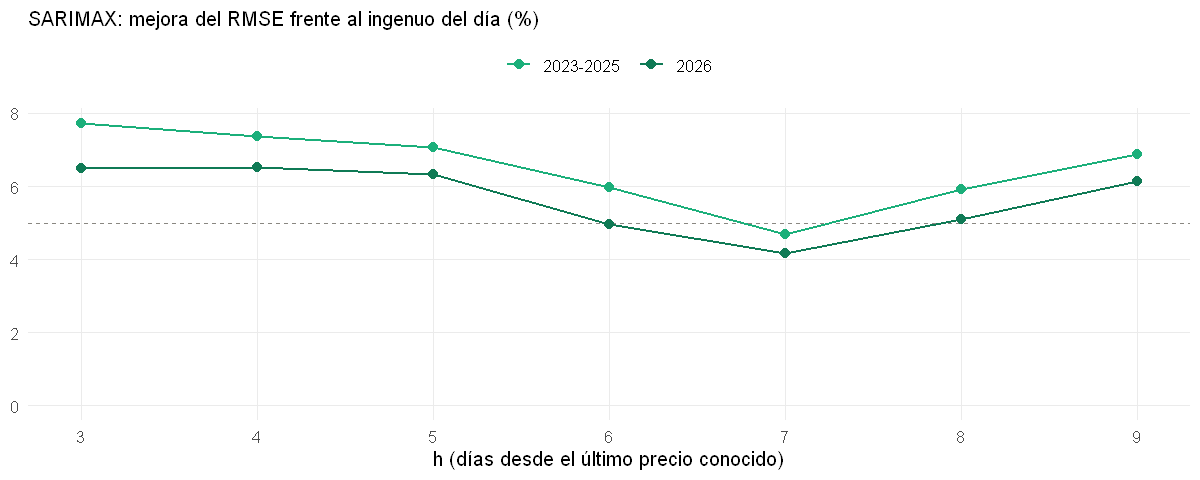

In [12]:
por_h <- test[, .(mejora = 100 * (1 - rmse(y - y_hat) / rmse(y))), by = .(periodo, h)]

ggplot(por_h, aes(h, mejora, color = periodo)) +
  geom_hline(yintercept = 5, linetype = "dashed", color = GRIS) +
  geom_line(linewidth = 0.8) + geom_point(size = 2.5) +
  scale_color_manual(values = c("2023-2025" = VERDE, "2026" = "#0f7a55"), name = NULL) +
  scale_x_continuous(breaks = HORIZONTES) + expand_limits(y = 0) +
  labs(title = "SARIMAX: mejora del RMSE frente al ingenuo del día (%)",
       x = "h (días desde el último precio conocido)", y = NULL) +
  tema

In [13]:
print(dcast(por_h, h ~ periodo, value.var = "mejora"))
por_año <- rbindlist(lapply(2023:2025, function(a) criterio(test[periodo == "2023-2025" & year(fecha) == a])[1][, año := a]))
por_año[, .(año, rmse, rmse_ingenuo, mejora, p, cumple)]

Key: <h>
       h 2023-2025  2026
   <int>     <num> <num>
1:     3     7.736 6.494
2:     4     7.381 6.520
3:     5     7.076 6.338
4:     6     5.965 4.962
5:     7     4.682 4.179
6:     8     5.908 5.094
7:     9     6.879 6.128


año,rmse,rmse_ingenuo,mejora,p,cumple
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
2023,0.5214,0.5441,4.162,5.153e-03,FALSE
2024,0.4776,0.5084,6.061,2.635e-03,TRUE
2025,0.4010,0.4474,10.370,4.799e-12,TRUE


La mejora baja desde $h = 3$ hasta $h = 7$ y vuelve a subir en 8 y 9. En $h = 7$ el último precio
conocido es del mismo día de la semana que el día pronosticado, así que el ingenuo ya trae el
ciclo semanal y el modelo tiene menos que agregar. Por años, 2023 queda en 4,2% y no cumple el
criterio; 2024 y 2025 sí (6,1% y 10,4%).

### Resultados con el formato de Salazar-Peña et al. (2025)

Los resultados también se presentan como en Salazar-Peña et al. (2025), que compara una LSTM, una
Bi-LSTM y un Transformer para pronosticar irradiancia solar. Para cada modelo ese trabajo reporta
por horizonte el MAE, el RMSE, el nRMSE (el RMSE dividido por el promedio real), el MBE (el error
medio) y el MAPE, con un intervalo t al 95%, y el MAPE por hora del día. Aquí se calculan en
COP/kWh, volviendo el pronóstico del logaritmo a pesos con la exponencial. El error es pronóstico
menos real: un MBE negativo quiere decir que el modelo se quedó por debajo. El skill score es la
mejora del RMSE frente al ingenuo del día, como en la figura 24 del paper, pero medida en pesos.

In [14]:
pesos <- test[, .(periodo, fecha, hora, h, real = exp(lp_t + y), SARIMAX = exp(lp_hat), ingenuo = exp(lp_t))]

metricas <- function(pron, real) {
  e <- pron - real
  list(MAE = mean(abs(e)), RMSE = rmse(e), nRMSE = 100 * rmse(e) / mean(real), MBE = mean(e),
       MAPE = 100 * mean(abs(e) / real))
}

semana <- rbind(pesos[, c(modelo = "SARIMAX", metricas(SARIMAX, real)), by = periodo],
                pesos[, c(modelo = "ingenuo del día", metricas(ingenuo, real)), by = periodo])
semana[, skill := 100 * (1 - RMSE / RMSE[modelo == "ingenuo del día"]), by = periodo]
semana[order(periodo), lapply(.SD, function(x) if (is.numeric(x)) round(x, 1) else x)]

periodo,modelo,MAE,RMSE,nRMSE,MBE,MAPE,skill
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2023-2025,SARIMAX,148.8,242.1,49.3,-15.3,39.0,5.8
2023-2025,ingenuo del día,150.1,257.1,52.3,1.3,40.1,0.0
2026,SARIMAX,122.9,176.5,36.2,-29.2,30.4,6.4
2026,ingenuo del día,127.1,188.5,38.6,-8.3,32.4,0.0


En pesos SARIMAX mejora al ingenuo casi lo mismo que en logaritmo: el skill score de la semana es
5,8% en 2023-2025 y 6,4% en 2026, frente a 6,4% y 5,6% del criterio. El MAE y el MAPE quedan apenas
por debajo de los del ingenuo (149 frente a 150 COP/kWh y 39,0% frente a 40,1% en 2023-2025). El
modelo se queda corto en promedio, 15 COP/kWh en 2023-2025 y 29 en 2026: la exponencial del
pronóstico del logaritmo se acerca a la mediana del precio, que queda por debajo de su media
porque el precio tiene picos hacia arriba (Duan, 1983).

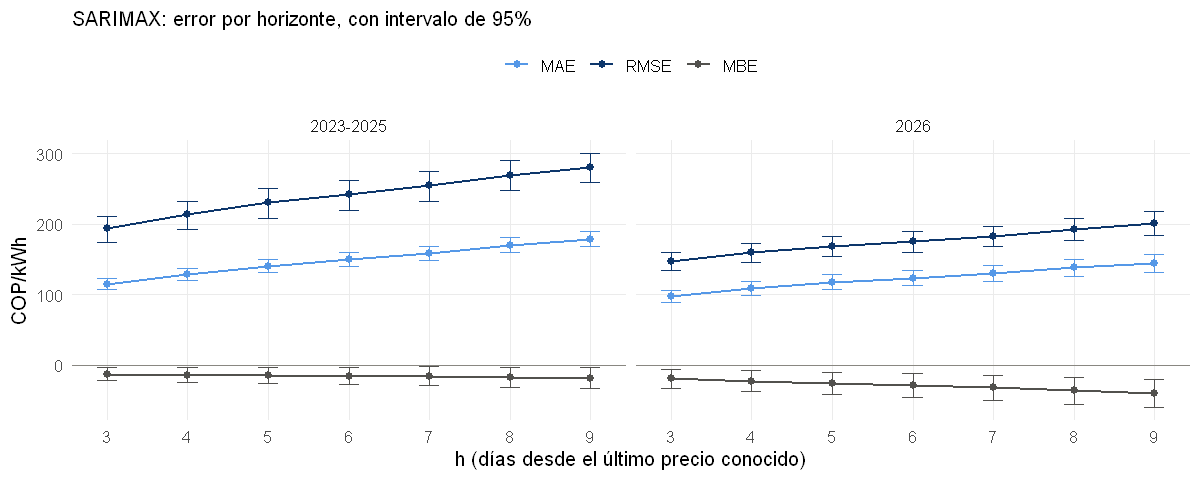

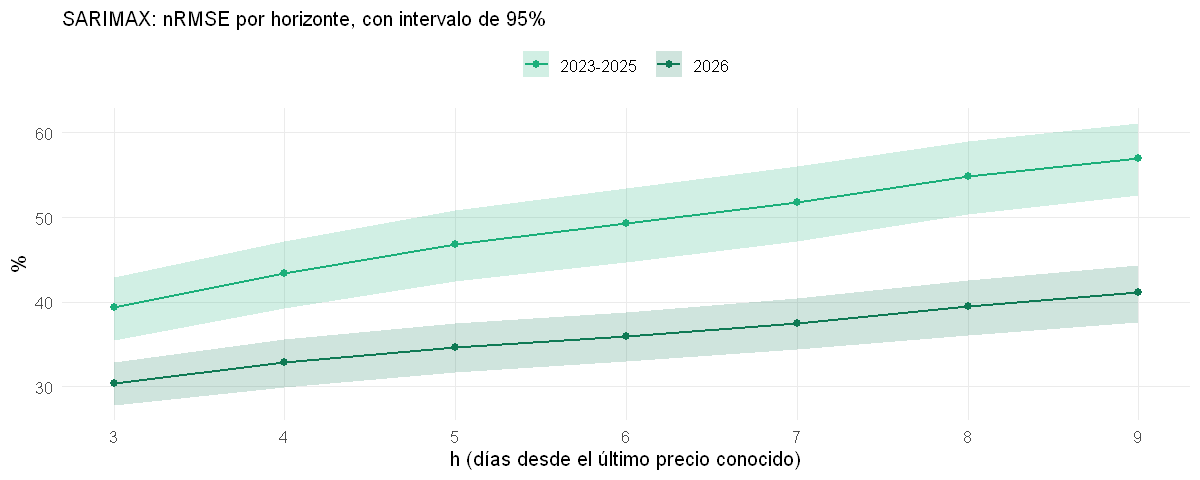

In [15]:
por_horizonte <- function(p) {
  # el intervalo t al 95% se calcula con el error promedio de cada día de pronóstico,
  # porque las 24 horas de un mismo día no son independientes
  dia <- p[, .(MAE = mean(abs(e)), MBE = mean(e), MSE = mean(e^2), real = mean(real), APE = mean(abs(e) / real)),
           by = .(periodo, h, fecha)]
  dia[, {
    k <- qt(0.975, .N - 1) / sqrt(.N)
    rm <- sqrt(pmax(mean(MSE) + c(0, -1, 1) * k * sd(MSE), 0))
    .(MAE = mean(MAE), MAE_inf = mean(MAE) - k * sd(MAE), MAE_sup = mean(MAE) + k * sd(MAE),
      MBE = mean(MBE), MBE_inf = mean(MBE) - k * sd(MBE), MBE_sup = mean(MBE) + k * sd(MBE),
      RMSE = rm[1], RMSE_inf = rm[2], RMSE_sup = rm[3],
      nRMSE = 100 * rm[1] / mean(real), nRMSE_inf = 100 * rm[2] / mean(real), nRMSE_sup = 100 * rm[3] / mean(real),
      MAPE = 100 * mean(APE))
  }, by = .(periodo, h)]
}

ph <- por_horizonte(pesos[, .(periodo, fecha, hora, h, real, e = SARIMAX - real)])
largo <- rbindlist(lapply(c("MAE", "RMSE", "MBE"), function(m)
  ph[, .(periodo, h, metrica = m, valor = get(m), inf = get(paste0(m, "_inf")), sup = get(paste0(m, "_sup")))]))
largo[, metrica := factor(metrica, c("MAE", "RMSE", "MBE"))]

# como las figuras 15, 18 y 21 del paper
print(ggplot(largo, aes(h, valor, color = metrica)) +
  geom_hline(yintercept = 0, color = GRIS) +
  geom_errorbar(aes(ymin = inf, ymax = sup), width = 0.25) +
  geom_line(linewidth = 0.8) + geom_point(size = 2) +
  facet_wrap(~periodo) +
  scale_color_manual(values = COLOR_METRICA, name = NULL) +
  scale_x_continuous(breaks = HORIZONTES) +
  labs(title = "SARIMAX: error por horizonte, con intervalo de 95%", x = EJE_H, y = "COP/kWh") +
  tema)

# como las figuras 16, 19 y 22 del paper
print(ggplot(ph, aes(h, nRMSE, color = periodo, fill = periodo)) +
  geom_ribbon(aes(ymin = nRMSE_inf, ymax = nRMSE_sup), alpha = 0.2, color = NA) +
  geom_line(linewidth = 0.8) + geom_point(size = 2) +
  scale_color_manual(values = c("2023-2025" = VERDE, "2026" = "#0f7a55"), name = NULL) +
  scale_fill_manual(values = c("2023-2025" = VERDE, "2026" = "#0f7a55"), name = NULL) +
  scale_x_continuous(breaks = HORIZONTES) +
  labs(title = "SARIMAX: nRMSE por horizonte, con intervalo de 95%", x = EJE_H, y = "%") +
  tema)

In [16]:
dcast(ph[, lapply(.SD, round, 1), by = .(periodo, h), .SDcols = c("MAE", "RMSE", "nRMSE", "MBE", "MAPE")],
      h ~ periodo, value.var = c("MAE", "RMSE", "nRMSE", "MBE", "MAPE"))

h,MAE_2023-2025,MAE_2026,RMSE_2023-2025,RMSE_2026,nRMSE_2023-2025,nRMSE_2026,MBE_2023-2025,MBE_2026,MAPE_2023-2025,MAPE_2026
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
3,115.0,97.6,193.6,147.8,39.4,30.4,-12.7,-19.4,29.1,23.8
4,129.1,108.9,213.3,159.9,43.4,32.8,-13.9,-22.8,32.9,26.8
5,140.6,117.5,230.3,169.0,46.9,34.7,-14.7,-26.1,36.3,29.1
6,149.6,123.7,242.0,175.5,49.2,36.0,-15.3,-29.0,39.0,30.8
7,158.2,130.4,254.4,183.3,51.8,37.5,-15.7,-31.8,41.9,32.5
8,170.2,138.1,269.6,193.2,54.9,39.4,-17.1,-35.9,45.6,34.4
9,179.0,144.5,280.4,201.7,57.0,41.1,-18.1,-39.6,48.3,35.9


El MAE y el RMSE crecen con el horizonte: en 2023-2025 el MAE va de 115 COP/kWh en $h = 3$ a 179
en $h = 9$, y el nRMSE de 39% a 57%. La ventaja frente al ingenuo cambia poco: el skill score queda
entre 4% y 7% en todos los horizontes, con el mínimo en $h = 7$. El MBE es negativo y casi
constante en 2023-2025, entre $-13$ y $-18$ COP/kWh, sin que su intervalo toque el cero; en 2026
crece de $-19$ a $-40$.

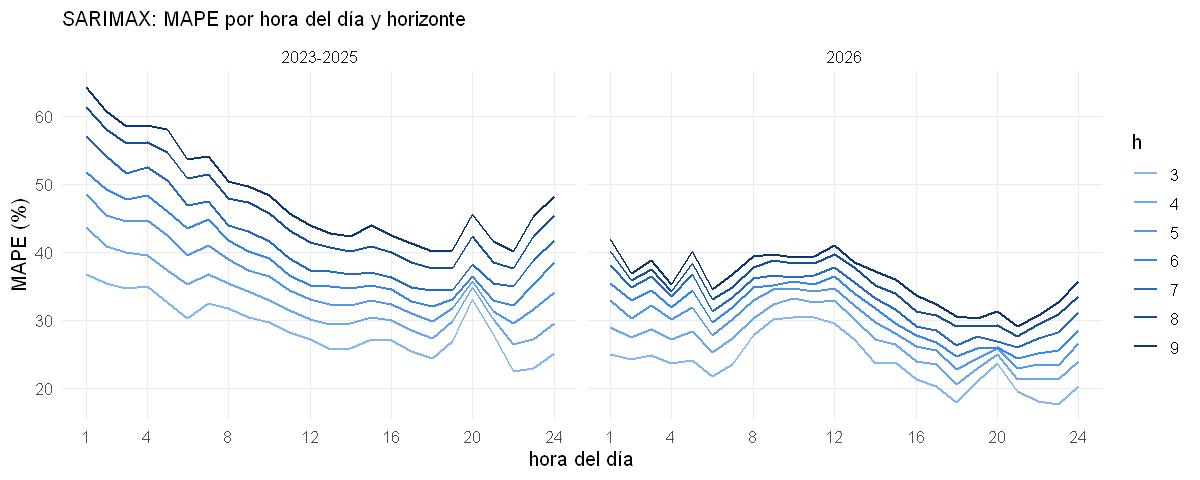

In [17]:
# como las figuras 17, 20 y 23 del paper: una curva por horizonte, de h = 3 (clara) a h = 9 (oscura)
mh <- pesos[, .(MAPE = 100 * mean(abs(SARIMAX - real) / real)), by = .(periodo, h, hora)]
ggplot(mh, aes(hora, MAPE, color = factor(h))) +
  geom_line(linewidth = 0.7) +
  facet_wrap(~periodo) +
  scale_color_manual(values = setNames(AZULES, HORIZONTES), name = "h") +
  scale_x_continuous(breaks = c(1, 4, 8, 12, 16, 20, 24)) +
  labs(title = "SARIMAX: MAPE por hora del día y horizonte", x = "hora del día", y = "MAPE (%)") +
  tema + theme(legend.position = "right")

El MAPE crece con el horizonte en las 24 horas. En 2023-2025 es más alto en la madrugada (64% en
la hora 1 con $h = 9$) y más bajo en la hora 22; en la hora 20, la del pico de la noche, sube. En
2026 la mañana, entre las horas 8 y 12, tiene errores tan altos como los de la madrugada.

### Intervalos de 80%

El modelo también da un intervalo de pronóstico. Si estuviera bien calibrado, el precio real
caería dentro del intervalo de 80% el 80% de las veces.

In [18]:
test[, dentro := lp_t + y >= lo80 & lp_t + y <= hi80]
cobertura <- dcast(test[, .(cobertura = 100 * mean(dentro)), by = .(periodo, h)], h ~ periodo, value.var = "cobertura")
print(cobertura)
test[, .(cobertura_semana = 100 * mean(dentro)), by = periodo]

Key: <h>
       h 2023-2025  2026
   <int>     <num> <num>
1:     3     72.98 78.91
2:     4     71.79 77.55
3:     5     71.39 76.06
4:     6     71.24 74.97
5:     7     70.58 73.47
6:     8     70.08 73.17
7:     9     69.38 73.40


periodo,cobertura_semana
<chr>,<dbl>
2023-2025,71.06
2026,75.38


Los intervalos son demasiado estrechos: cubren el precio real 71% de las veces en 2023-2025 y 75%
en 2026, y la cobertura baja a medida que el horizonte se aleja (de 73% en $h = 3$ a 69% en
$h = 9$ en 2023-2025). El modelo subestima la incertidumbre del precio.

### Semana del 9 al 15 de octubre de 2026

Pronóstico hecho con los precios conocidos hasta el 6 de octubre. Se guardó antes de descargar el
precio real de esa semana. Es una sola semana: sirve para ver cómo se comporta el modelo, no para
evaluarlo.

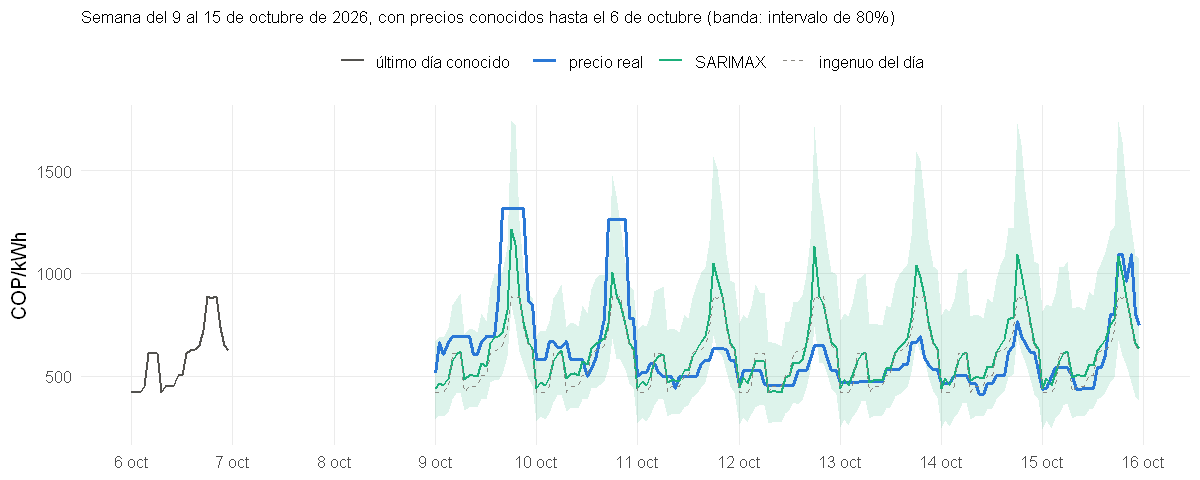

In [19]:
fin <- fread(file.path(SAR, "pronostico_final.csv"))[, fecha_objetivo := as.Date(fecha) + h]
real <- fread(file.path(XGB, "precio_real_final.csv"))[, fecha_objetivo := as.Date(fecha_objetivo)]
sem <- merge(fin, real, by = c("fecha_objetivo", "hora"))
t0 <- as.Date(fin$fecha[1])
sem[, `:=`(momento = as.POSIXct(fecha_objetivo, tz = "UTC") + (hora - 1) * 3600, SARIMAX = exp(lp_hat),
           ingenuo = exp(LP[cbind(match(t0, FECHAS), hora)]))]
previo <- data.table(momento = as.POSIXct(t0, tz = "UTC") + (0:23) * 3600, precio = exp(LP[match(t0, FECHAS), ]))

# como las figuras 28 a 37 del paper: el pronóstico frente al real
colores <- c("último día conocido" = "#52514e", "precio real" = AZUL, SARIMAX = VERDE, "ingenuo del día" = GRIS)
ggplot(sem, aes(momento)) +
  geom_ribbon(aes(ymin = exp(lo80), ymax = exp(hi80)), fill = VERDE, alpha = 0.15) +
  geom_line(data = previo, aes(y = precio, color = "último día conocido"), linewidth = 0.6) +
  geom_line(aes(y = precio_real, color = "precio real"), linewidth = 0.9) +
  geom_line(aes(y = SARIMAX, color = "SARIMAX"), linewidth = 0.7) +
  geom_line(aes(y = ingenuo, color = "ingenuo del día"), linewidth = 0.5, linetype = "dashed") +
  scale_color_manual(values = colores, breaks = names(colores), name = NULL) +
  scale_x_datetime(date_breaks = "1 day", labels = function(x) paste(as.integer(format(x, "%d")), "oct")) +
  labs(title = "Semana del 9 al 15 de octubre de 2026, con precios conocidos hasta el 6 de octubre (banda: intervalo de 80%)",
       x = NULL, y = "COP/kWh") +
  tema + theme(plot.title = element_text(size = 10))

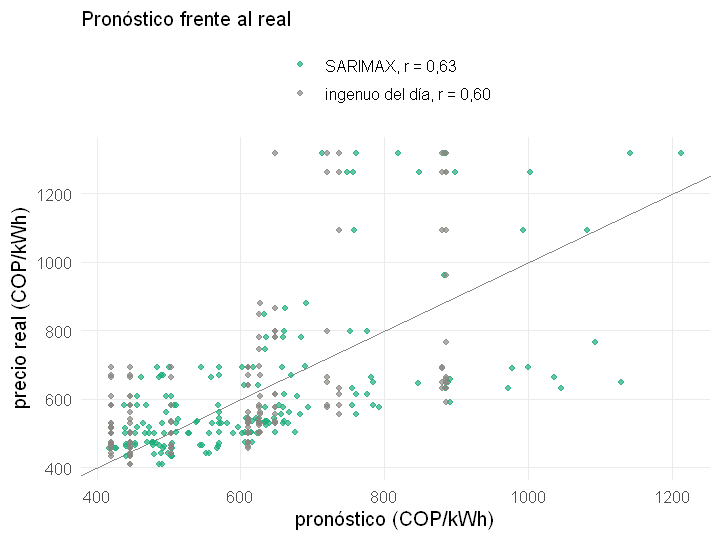

In [20]:
# y su correlación de Pearson con el precio real
options(repr.plot.width = 6, repr.plot.height = 4.5)
r <- function(x) sub(".", ",", sprintf("%.2f", cor(sem$precio_real, x)), fixed = TRUE)
disp <- rbind(sem[, .(modelo = paste0("SARIMAX, r = ", r(SARIMAX)), pron = SARIMAX, real = precio_real)],
              sem[, .(modelo = paste0("ingenuo del día, r = ", r(ingenuo)), pron = ingenuo, real = precio_real)])
disp[, modelo := factor(modelo, unique(modelo))]
ggplot(disp, aes(pron, real, color = modelo)) +
  geom_abline(color = GRIS) +
  geom_point(size = 1.4, alpha = 0.7) +
  scale_color_manual(values = setNames(c(VERDE, GRIS), levels(disp$modelo)), name = NULL) +
  labs(title = "Pronóstico frente al real", x = "pronóstico (COP/kWh)", y = "precio real (COP/kWh)") +
  tema + theme(legend.direction = "vertical")

In [21]:
sem[, .(modelo = c("SARIMAX", "ingenuo del día"),
        rmse_log = c(rmse(log(precio_real / SARIMAX)), rmse(log(precio_real / ingenuo))),
        mape = 100 * c(mean(abs(SARIMAX / precio_real - 1)), mean(abs(ingenuo / precio_real - 1))),
        mbe = c(mean(SARIMAX - precio_real), mean(ingenuo - precio_real)),
        pearson = c(cor(precio_real, SARIMAX), cor(precio_real, ingenuo)),
        cobertura_80 = c(100 * mean(precio_real >= exp(lo80) & precio_real <= exp(hi80)), NA))]

modelo,rmse_log,mape,mbe,pearson,cobertura_80
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SARIMAX,0.2176,17.94,3.683,0.6339,94.05
ingenuo del día,0.2343,18.71,-31.991,0.5991,NA


En esa semana SARIMAX tuvo menos error que el ingenuo del día (0,218 frente a 0,234 en RMSE en
logaritmo y MAPE de 17,9% frente a 18,7%), casi sin sesgo, y el intervalo cubrió 94% de las horas.
Su correlación con el precio real fue 0,63, frente a 0,60 del ingenuo. El modelo repite cada día
el pico de la noche que traían los últimos precios conocidos. Desde el 11 de octubre el precio
real se calmó y en esas noches el pronóstico quedó por encima.

## Hallazgos

1. Con solo el precio pasado, el ciclo semanal y el festivo, SARIMAX supera al ingenuo del día en
   todos los bloques del test y en los dos periodos. Cumple el criterio, pero con poco margen: 6,4%
   en 2023-2025 y 5,6% en 2026 en la semana completa. En la validación había quedado en 4,7%, y en
   2023, el año más volátil del test, tampoco llega al 5%.
2. Lo que aporta el modelo es sobre todo el ciclo semanal. Por eso su ventaja es menor en $h = 7$,
   donde el ingenuo del día ya es el mismo día de la semana.
3. Ninguna variable exógena mejoró el pronóstico de la semana. La única que pasó los filtros,
   `holgura_rel`, no cambió el error en la validación, y un orden distinto por hora tampoco.
4. Los intervalos de 80% cubren menos de lo que deberían (71% y 75%). Si se quieren usar como rango
   de decisión, habría que ampliarlos o calibrarlos.
5. En pesos, con el formato de Salazar-Peña et al. (2025), la ventaja se mantiene: skill score de
   5,8% en 2023-2025 y 6,4% en 2026, y entre 4% y 7% en todos los horizontes de 2023-2025. Se
   queda corto en promedio, pero menos que XGBoost y la LSTM (MBE de $-15$ COP/kWh en 2023-2025).

## Referencias

- Diebold, F. y Mariano, R. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253-263.
- Duan, N. (1983). Smearing estimate: a nonparametric retransformation method. *Journal of the American Statistical Association*, 78(383), 605-610.
- Hyndman, R. y Khandakar, Y. (2008). Automatic time series forecasting: the forecast package for R. *Journal of Statistical Software*, 27(3), 1-22.
- Ljung, G. y Box, G. (1978). On a measure of lack of fit in time series models. *Biometrika*, 65(2), 297-303.
- Newey, W. y West, K. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703-708.
- Salazar-Peña, N., Palma-Vergara, A., Montes-Vera, M., Vargas-Torres, M. A., Hernández Vanegas, R., Amador, M., Rojas, B., Salinas, A., Velasco, A., Tabares, A. y González-Mancera, A. (2025). Intra-day solar and power forecast for optimization of intraday market participation. *arXiv*, 2501.09551v3.